# Five scenarios with the Chile macro-fiscal model

The deterministic macro-fiscal / pension model, loaded from the file the
[loading notebook](chile_macrofiscal_deterministic.ipynb) saved.

## Summary

Each scenario moves **one exogenous variable** of the model away from the baseline and keeps
everything else as it is. Together they cover the main channels into public debt: tax revenue,
pension spending, health spending, labour supply and the copper price.

| Scenario | Shocked variable | Shock | Channel |
|---|---|---|---|
| VAT +2 pp | `TAU_CONS` | +0.02 from 2027 | VAT revenue |
| Pension benefits +0.5 % of GDP | `G_P_STEP` | +0.005 in 2026, a permanent step | pension spending |
| Health elasticity 0.50 | `HEALTH_EL` | 0.66 → 0.50 from 2025 | health spending |
| Female participation +8 pp | `P_F_1559` | +0.8 pp a year 2026–2035, then held | labour supply, GDP |
| Copper price −20 % | `PCOPPER_SS` | × 0.8 from 2025 | mining revenue |

:::{figure} graph/scenarios/Gross government debt, percent of GDP, level.png
:alt: Gross government debt, percent of GDP, baseline and the five scenarios, 2024-2070
:width: 100%

Gross government debt, percent of GDP, in the baseline and the five scenarios. The figure is
made at the end of the notebook.
:::

### Results

Debt in 2070 is 285 % of GDP in the baseline. Against that:

- **Health elasticity 0.50** lowers it by 108 points, the largest effect of the five. Health is
  the fastest growing spending item, so slowing it compounds the most.
- **VAT +2 pp** lowers it by 69 points. Revenue rises by 1.1 % of GDP at first, but by only 0.8 %
  in 2070, because the consumption rate, the VAT base, falls as the population ages.
- **Pension benefits +0.5 % of GDP** raise it by 42 points; the extra spending grows to 0.7 % of
  GDP as the number of pensioners rises.
- **Female participation +8 pp** lowers it by only 2.5 points, although the labour force is 4–5 %
  larger. Spending and taxes are shares of GDP in this model, so a higher GDP level does not
  change the primary balance; it only helps through the debt ratio's denominator.
- **Copper price −20 %** *lowers* debt, by 5.6 points. Mining GDP is taxed at `T_C` = 16.5 %,
  non-mining GDP at about 22 % (13 % plus VAT on consumption), so a smaller mining share of GDP
  raises average revenue slightly. The model has no other link from the copper price to the budget.

The shocks are illustrations of a plausible size, not calibrated policy proposals. The baseline
itself has debt rising without bound (see the loading notebook), so the scenarios are best read
as **differences from the baseline**, which the table at the end shows.

### How the scenarios were chosen

The earlier, stochastic version of the model (`pensionsmodel/fromzip`) had fourteen scenarios.
Several of them use switches that the deterministic do-file does not have (the retirement-age
branches `D_RET*`, `D_HEALTH_OLD`, `D_SCHOOL_AGE`, `P_CHANGE`). The five here use variables that
are in this model, one each:

- **VAT** and **copper** are the two revenue levers of the earlier notebook (`vat_plus_2pp`,
  `copper_bust`); the copper price is lowered by 20 % instead of set to 3.00.
- **Pensions** and **health** are the two spending items that ageing drives. Health is the fastest
  growing item in the baseline, so its elasticity is the natural lever; for pensions a benefit
  increase is the policy question, entered through the step variable the model already uses for
  the 2025 OECD step.
- **Female participation** replaces the retirement-age and participation scenarios: it raises
  labour supply and so GDP, the denominator of every ratio.

In [1]:
from modelclass import model
import pandas as pd
%matplotlib inline

model.widescreen()
model.scroll_off()

<IPython.core.display.Javascript object>

## Load the model and solve the baseline

`data/chilepens.pcim` holds the model and the data it was solved on. `run=True` solves it again
over the same years, 2025–2070, and `keep='Baseline'` stores the solution under that name, so the
scenarios can be compared with it.

In [2]:
mchile, bline = model.modelload('data/chilepens', run=True, keep='Baseline')

# shares of GDP are shown multiplied by 100, so the chart and table titles say percent
pct = {v: d.replace('share of GDP', 'percent of GDP')
       for v, d in mchile.var_description.items() if 'share of GDP' in d}

Zipped file read:  data\chilepens.pcim


## Making a scenario

Every scenario takes the same three steps:

1. `bline.upd('<start end> VARIABLE operator value')` makes a copy of the baseline data with one
   variable changed over the years in `< >`. The operator `+` adds, `*` multiplies, `=` sets, and
   `=diff` sets the yearly change; `--kg` keeps the new level after the window.
2. `mchile(scenario_df, 2025, 2070, keep='name')` solves the model and stores the solution under
   that name.
3. `mchile.plot(...)` and `mchile.table(...)` show the stored solutions; `scenarios='Baseline|name'`
   picks which. Shares of GDP are multiplied by 100 to show percent.

## 1. VAT +2 percentage points — `TAU_CONS`

`TAU_CONS` is the VAT rate applied to the consumption share of non-commodity GDP
(`T_NC = T2_NC + T_IVA*CONS_RATE`). Raising it by 2 points from 2027 raises non-mining revenue.
The base shrinks over time, since the consumption rate falls as the population ages, so the gain
in revenue falls too.

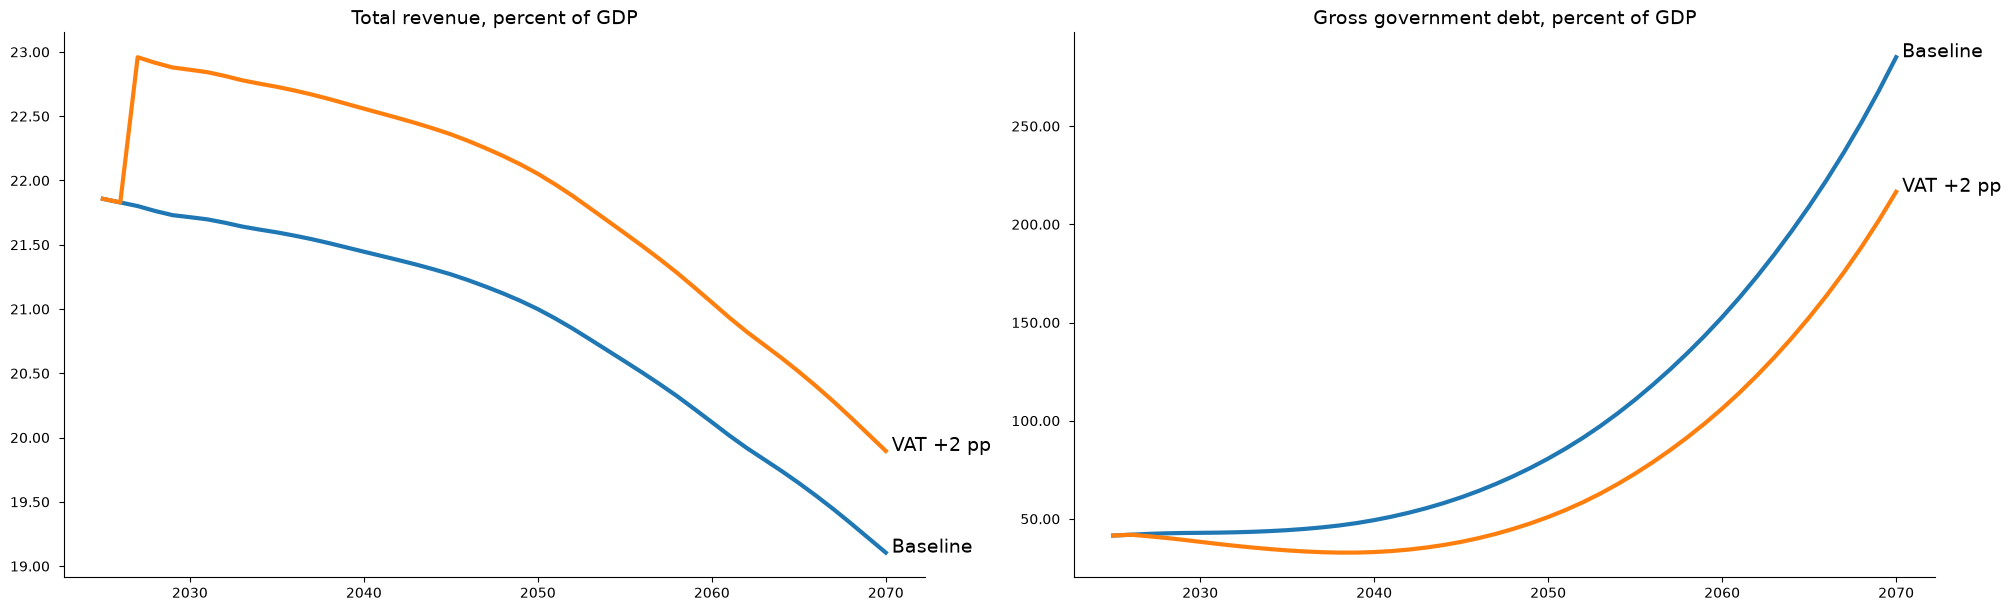

In [3]:
scenario = bline.upd('<2027 2070> TAU_CONS + 0.02')
_ = mchile(scenario, 2025, 2070, keep='VAT +2 pp', silent=1)
mchile.plot('REV_TOT B_G', scenarios='Baseline|VAT +2 pp', datatype='level', mul=100, custom_description=pct,
            legend=False, samefig=True).show

## 2. Pension benefits +0.5 % of GDP — `G_P_STEP`

Pension spending follows
`G_P_NOM_GDP = G_P_NOM_GDP(-1)*(PEN_RATIO/PEN_RATIO(-1))**(PENSION_EL*D_PEN_EL) + G_P_STEP`.
`G_P_STEP` is the one-off step the do-file uses for the OECD scenario (0.012 in 2025). Adding
0.005 in 2026 raises benefits by 0.5 % of GDP for good: the step is carried forward by the
lag, and from 2031 it grows with the number of pensioners like the rest of pension spending.

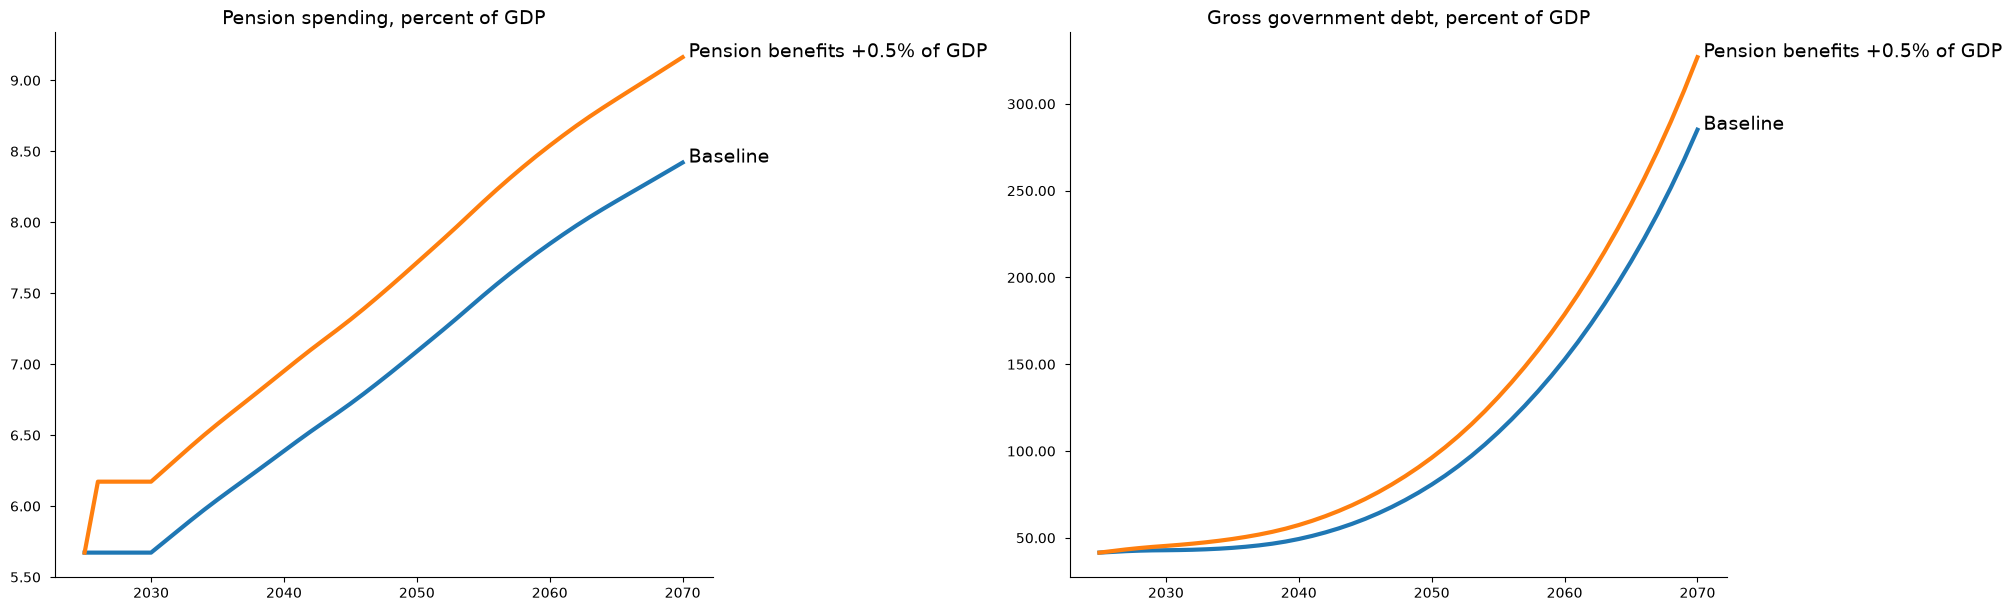

In [4]:
scenario = bline.upd('<2026> G_P_STEP + 0.005')
_ = mchile(scenario, 2025, 2070, keep='Pension benefits +0.5% of GDP', silent=1)
mchile.plot('G_P_NOM_GDP B_G', scenarios='Baseline|Pension benefits +0.5% of GDP', datatype='level',
            mul=100, custom_description=pct, legend=False, samefig=True).show

## 3. Health elasticity 0.50 — `HEALTH_EL`

Health spending grows with the share of people aged 80 and over:
`G_H_NOM_GDP = G_H_NOM_GDP(-1)*(OLD_RATIO/OLD_RATIO(-1))**HEALTH_EL`. In the baseline the elasticity
is 0.66 and health is the fastest growing spending item. An elasticity of 0.50 stands for cost
containment: spending still rises with ageing, but less per extra old person.

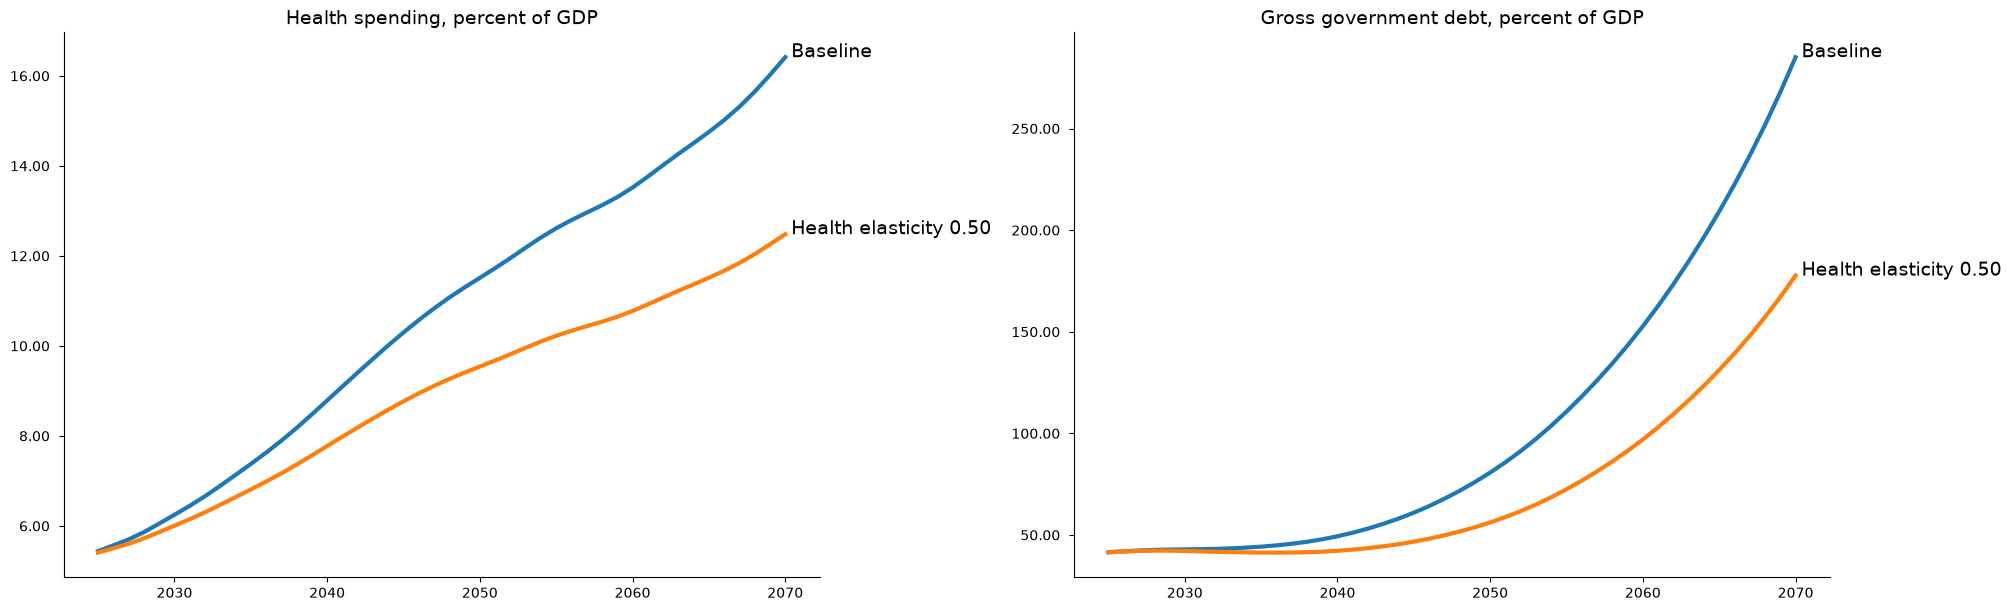

In [5]:
scenario = bline.upd('<2025 2070> HEALTH_EL = 0.50')
_ = mchile(scenario, 2025, 2070, keep='Health elasticity 0.50', silent=1)
mchile.plot('G_H_NOM_GDP B_G', scenarios='Baseline|Health elasticity 0.50', datatype='level', mul=100, custom_description=pct,
            legend=False, samefig=True).show

## 4. Female participation +8 percentage points — `P_F_1559`

The participation rate of women aged 15–59 is held at its 2022–2024 average, 0.62, in the
baseline. Here it rises by 0.8 points a year from 2026 to 0.70 in 2035 and stays there (`=diff`
sets the yearly change, `--kg` keeps the level after 2035). It is still below men's 0.78.

More workers raise effective labour, so real and nominal GDP; spending and revenue are shares of
GDP, so the debt ratio falls only through the denominator: with a larger GDP the inherited debt is a
smaller share of it. The primary balance, as a share of GDP, does not change, so the effect on
debt is small.

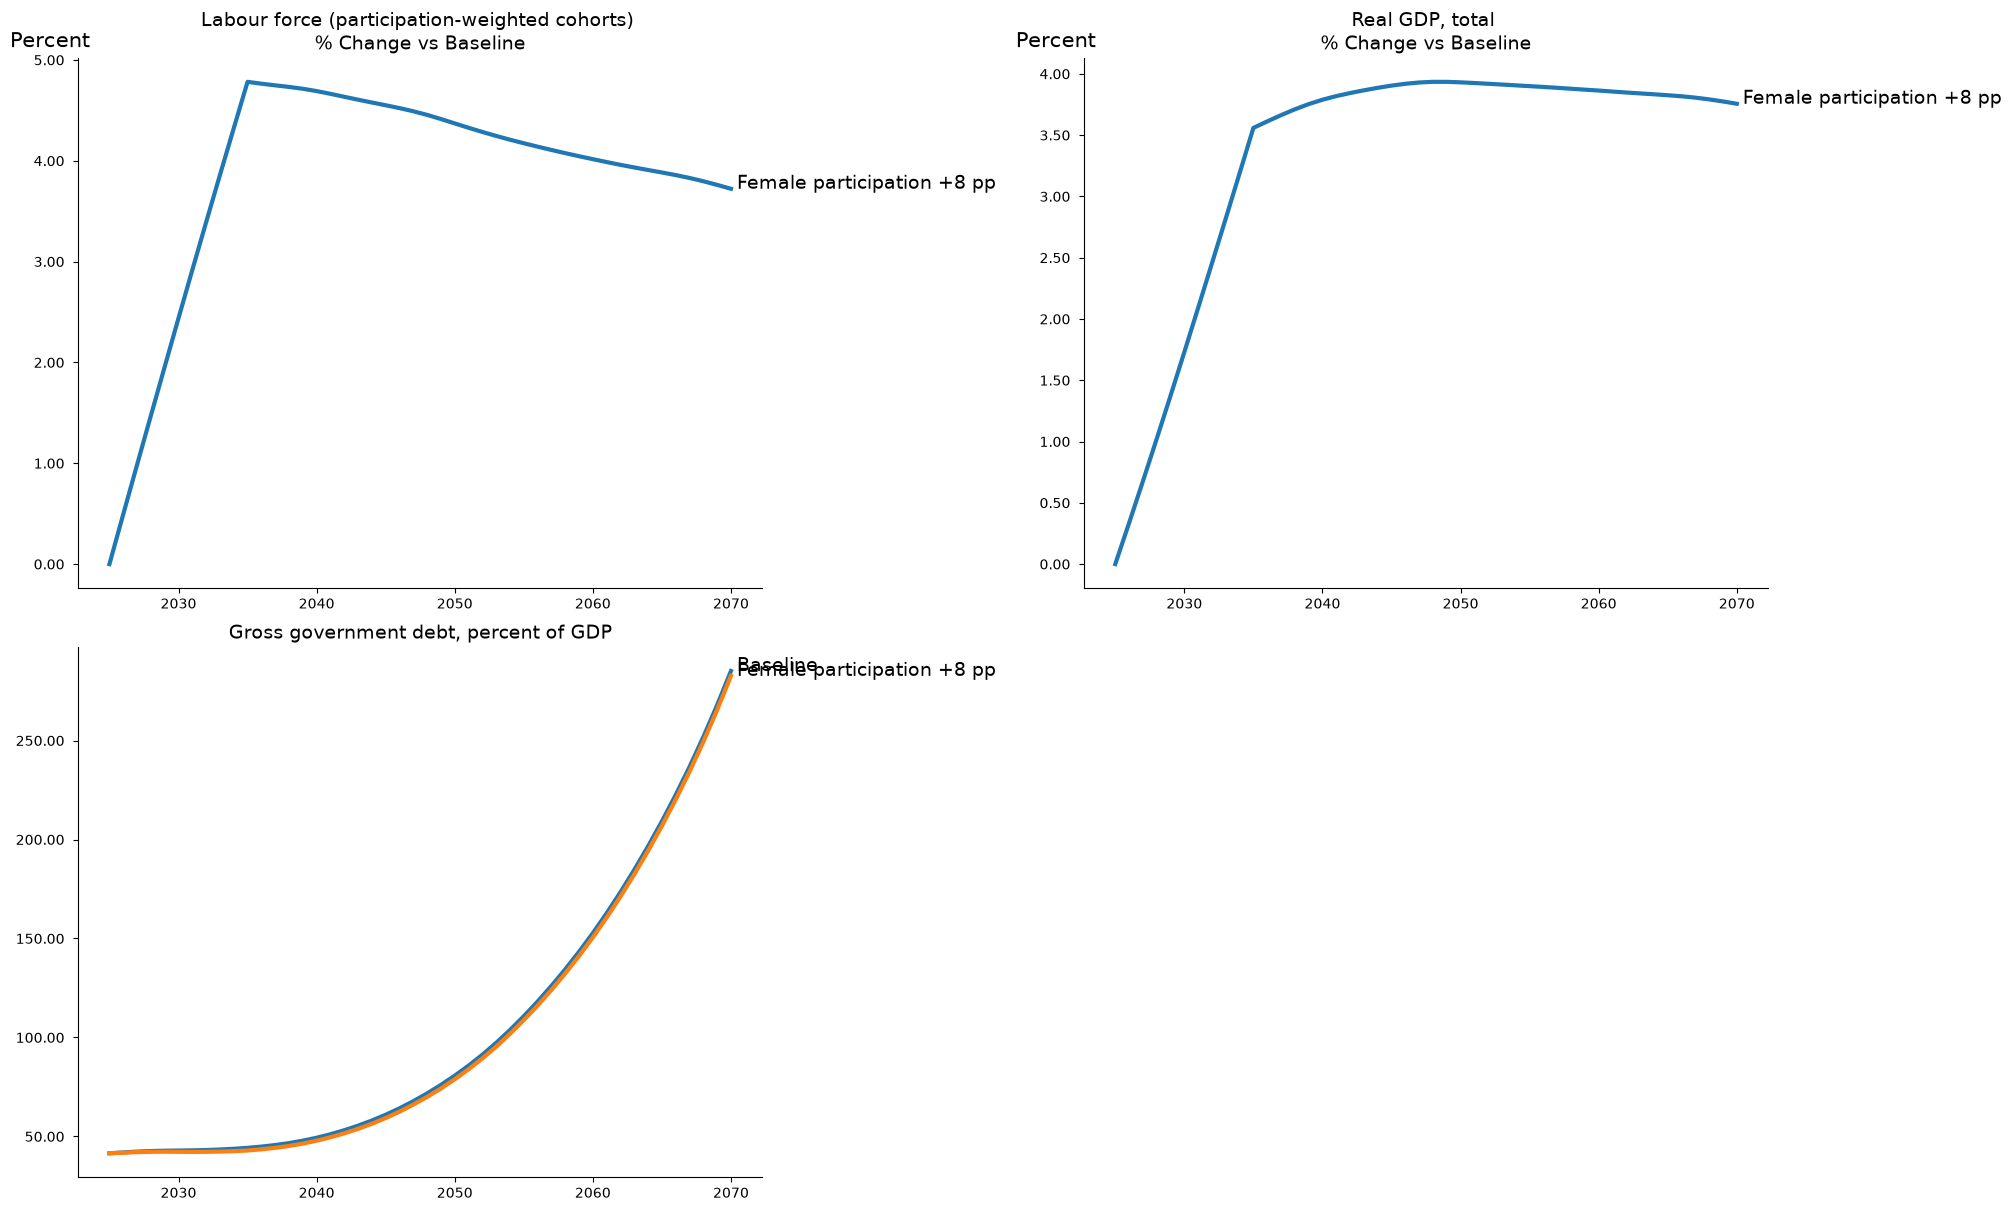

In [6]:
scenario = bline.upd('<2026 2035> P_F_1559 =diff 0.008 --kg')
_ = mchile(scenario, 2025, 2070, keep='Female participation +8 pp', silent=1)
(mchile.plot('LAB_MAR PIBREAL_TOT', scenarios='Baseline|Female participation +8 pp', datatype='difpctlevel',
             legend=False, samefig=True)
 | mchile.plot('B_G', scenarios='Baseline|Female participation +8 pp', datatype='level', mul=100, custom_description=pct,
               legend=False)).show

## 5. Copper price −20 % — `PCOPPER_SS`

`PCOPPER_SS` is the steady-state copper price, 4.38 dollars per pound; the real copper price
returns to it as an AR(1) process. Lowering it by 20 % from 2025 lowers the commodity deflator and
so nominal mining GDP and mining revenue (`REV_C`). Real output is not affected.

**Total revenue rises, though.** Mining GDP is taxed at `T_C` = 16.5 % and non-mining GDP at
`T_NC`, about 22 % (13 % plus VAT on consumption). A lower copper price makes mining a smaller
share of nominal GDP, so the average tax rate goes up and debt ends a little lower. The sign
depends on mining being taxed at a lower rate than the rest of the economy; with a mining tax
rate above `T_NC` a lower copper price would raise debt.

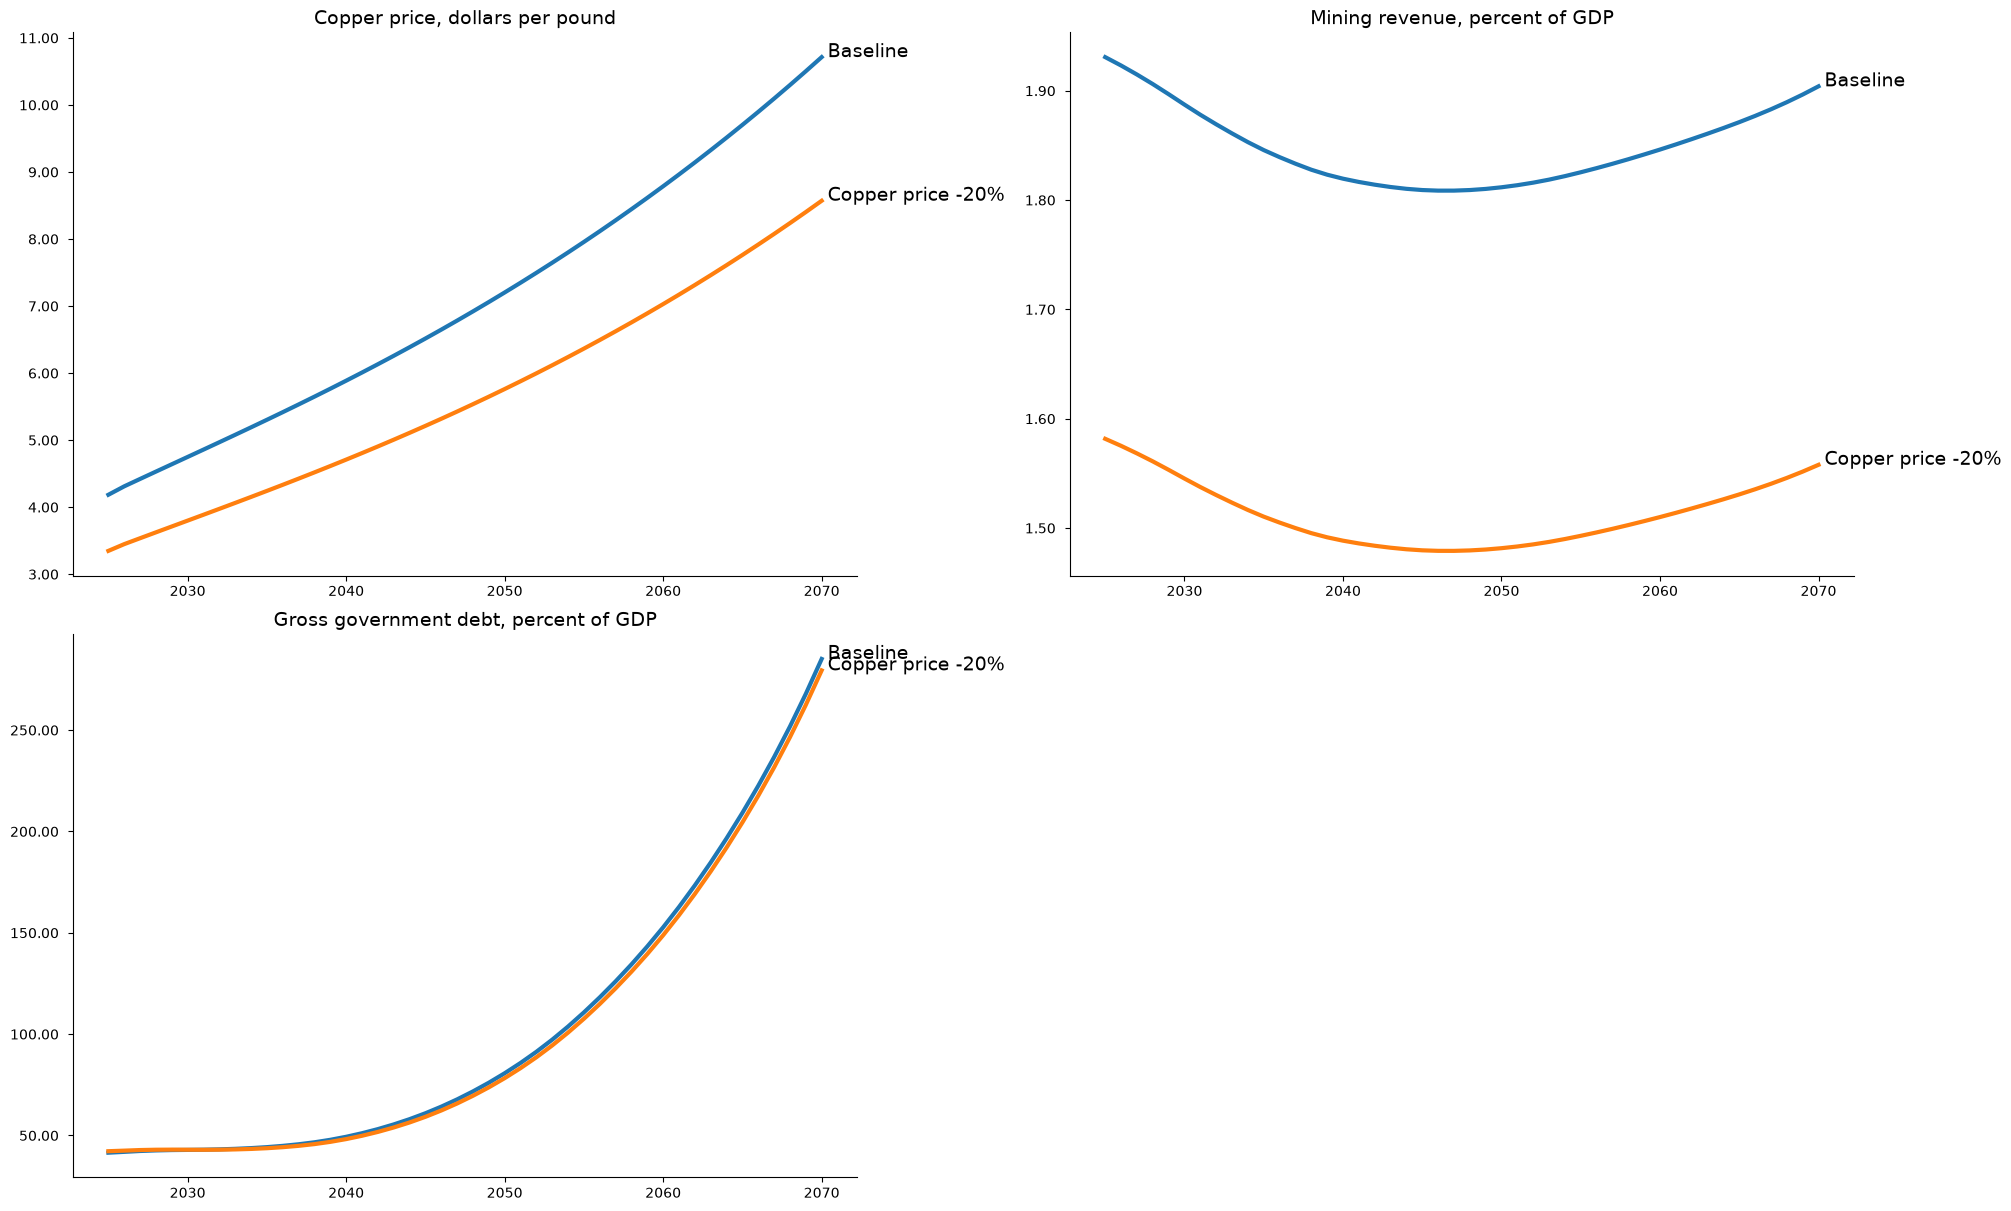

In [7]:
scenario = bline.upd('<2025 2070> PCOPPER_SS * 0.8')
_ = mchile(scenario, 2025, 2070, keep='Copper price -20%', silent=1)
(mchile.plot('PCOPPER', scenarios='Baseline|Copper price -20%', datatype='level', legend=False,
             samefig=True)
 | mchile.plot('REV_C B_G', scenarios='Baseline|Copper price -20%', datatype='level', mul=100, custom_description=pct,
               legend=False, samefig=True)).show

---
## All scenarios together

The change in the main fiscal ratios against the baseline, in percentage points of GDP. A
negative change in debt is an improvement.

In [8]:
mchile.table('B_G REV_TOT G_TOT', scenarios='*', datatype='diflevel', mul=100, custom_description=pct, dec=1,
             title='Change from the baseline, percentage points of GDP',
             timeslice=[2030, 2040, 2050, 2060, 2070])

Gross debt in each scenario, percent of GDP, and the change from the baseline in 2070:

In [9]:
YY = [2030, 2040, 2050, 2070]
debt = pd.DataFrame({name: 100*df.loc[YY, 'B_G'] for name, df in mchile.keep_solutions.items()}).T
debt['change 2070'] = debt[2070] - debt.loc['Baseline', 2070]
debt.style.format('{:.1f}')

,2030,2040,2050,2070,change 2070
Baseline,42.9,49.4,80.7,285.1,0.0
VAT +2 pp,38.3,33.1,50.9,216.6,-68.5
Pension benefits +0.5% of GDP,45.4,57.4,96.1,326.9,41.8
Health elasticity 0.50,42.1,42.2,56.2,177.6,-107.5
Female participation +8 pp,42.2,47.9,78.9,282.7,-2.5
Copper price -20%,43.0,48.2,78.3,279.5,-5.6


The figure in the summary at the top:

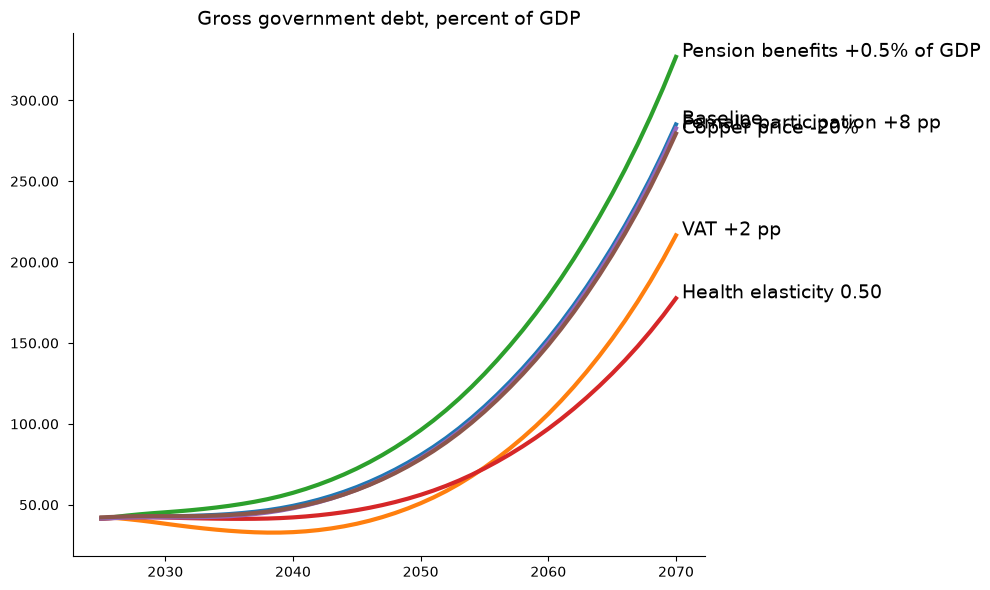

In [10]:
debtplot = mchile.plot('B_G', scenarios='*', datatype='level', mul=100, custom_description=pct, legend=False)

debtplot.savefigs(location='graph', experimentname='scenarios', extensions=['png'])   # for the summary
debtplot.show